# Iris — the actual classic

Yes, iris. Three classes, four features, 150 rows. I ran it because I wanted a clean visual for KNN vs LR vs decision tree, and to be honest a small sanity-check notebook is useful to have in the portfolio next to the harder ones.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from pathlib import Path

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(3)
ART = Path("artifacts"); ART.mkdir(exist_ok=True)

iris = load_iris()
X, y = iris.data, iris.target
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in y]
df.head()


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## pairplot — petal length and width basically separate the classes

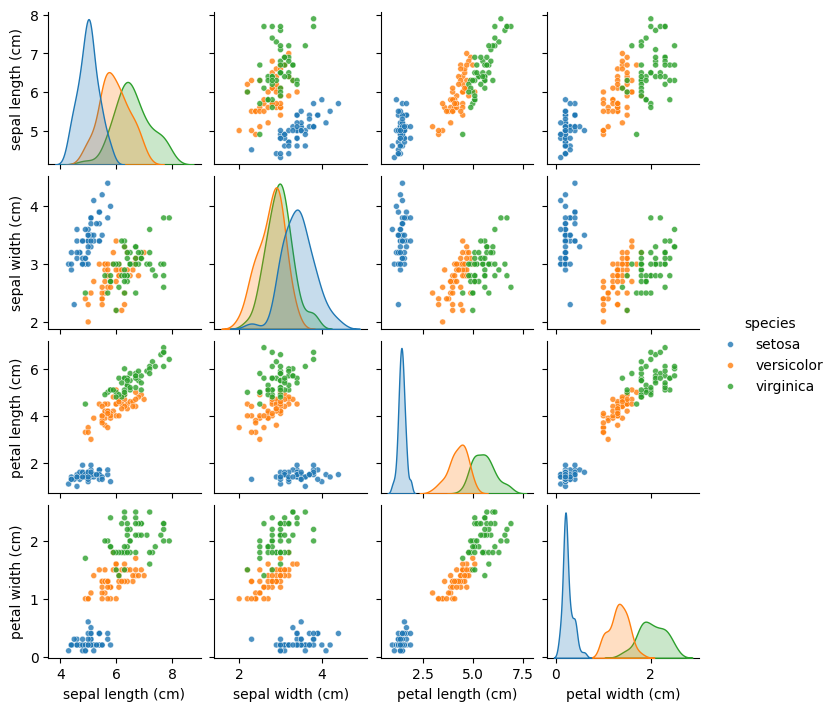

In [2]:
sns.pairplot(df, hue="species", height=1.8, plot_kws={"s": 18, "alpha": 0.8})
plt.savefig(ART / "pairplot.png", dpi=120)
plt.show()


## three classifiers, 5-fold CV

In [3]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=3)
models = {
    "KNN (k=5)": Pipeline([("sc", StandardScaler()), ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "LogReg":    Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=500))]),
    "DTree":     DecisionTreeClassifier(max_depth=4, random_state=3),
}
for name, m in models.items():
    s = cross_val_score(m, X, y, cv=skf, scoring="accuracy")
    print(f"{name:10s}  acc: mean={s.mean():.3f}  std={s.std():.3f}")


KNN (k=5)   acc: mean=0.940  std=0.039
LogReg      acc: mean=0.960  std=0.039
DTree       acc: mean=0.920  std=0.045


## hold-out confusion matrix using LR

test acc: 0.895


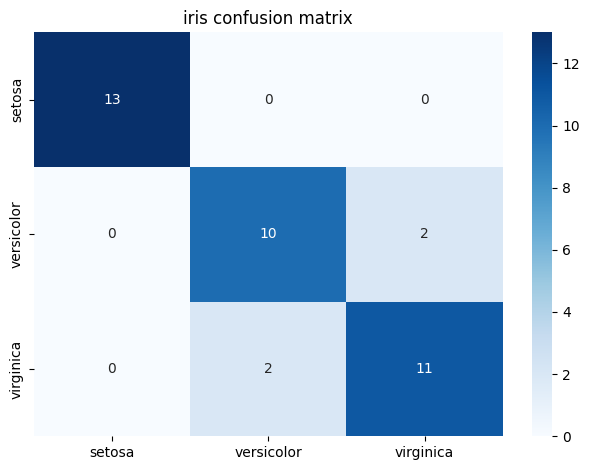

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=3)
lr = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=500))])
lr.fit(X_train, y_train)
pred = lr.predict(X_test)
print(f"test acc: {accuracy_score(y_test, pred):.3f}")

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.title("iris confusion matrix"); plt.tight_layout()
plt.savefig(ART / "cm.png", dpi=120); plt.show()


## notes

All three are basically tied. KNN is a hair behind because two flowers near the versicolor / virginica boundary are genuinely ambiguous in petal space. Nothing here will surprise anyone but it's a clean baseline to point at.
